# E2: CNN | 128 Mel bins | không SpecAugment
Nhánh GitHub: `05-E2-cnn-mel128`

Learning rate chọn trên fold 1 (chỉ dùng validation), sau đó chạy 5 fold (3 train, 1 validation, 1 test) và kiểm tra nhiễu Gaussian SNR 20/10/0 dB. Chạy lại ô sẽ tiếp tục từ fold còn dở.

In [1]:
!pip -q install soundfile
from google.colab import drive
drive.mount('/content/drive')
import sys
sys.path.append('/content/drive/MyDrive/ESC50')
from esc_lib import *
setup()

Mounted at /content/drive
GPU: Tesla T4 | VRAM 15.6 GB | torch 2.14.1+cu130 | CUDA 13.0
RAM trống 11.8 GB | ổ đĩa trống 120.8 GB
Mixup: BẬT | quick: False | kết quả lưu ở: /content/drive/MyDrive/ESC50/results_mixup


In [2]:
EXP_ID = "E2"
print(EXPERIMENTS[EXP_ID])
meta, X, X_DEV, y, folds = load_data()

{'model': 'cnn', 'n_mels': 128, 'specaug': False}


  0%|          | 0/2000 [00:00<?, ?it/s]

X: (2000, 110250) | y: (2000,) | nằm trên: cuda:0


## Tìm learning rate (fold 1)

In [3]:
lr = search_lr(EXP_ID)

E2: đã có learning rate được chọn = 0.001


## Chạy 5 fold và kiểm tra độ bền với nhiễu

In [4]:
runs, rob = run_exp(EXP_ID, lr)

E2 | fold 4:   0%|          | 0/80 [00:00<?, ?it/s]

[E2 | fold 4] acc 0.8750 | macro-F1 0.8706 | lr 0.001 | epoch tốt nhất 70 | 171s


E2 | fold 5:   0%|          | 0/80 [00:00<?, ?it/s]

[E2 | fold 5] acc 0.8475 | macro-F1 0.8362 | lr 0.001 | epoch tốt nhất 75 | 162s


## Kết quả

,fold,acc,macro_f1,lr,best_epoch,val_f1,train_time
0,1,0.8200,0.8129,0.001,73,0.8337,159.4509
1,2,0.8325,0.8264,0.001,57,0.8586,159.4208
2,3,0.8525,0.8512,0.001,78,0.8645,159.2255
3,4,0.8750,0.8706,0.001,70,0.8056,170.9315
4,5,0.8475,0.8362,0.001,75,0.8417,161.8036


E2: Accuracy 84.55 ± 2.09 | Macro-F1 83.95 ± 2.23 | 1,185,490 tham số


,acc,macro_f1
condition,,
Sạch,84.55,83.95
20 dB,68.45,68.62
10 dB,41.60,43.46
0 dB,7.45,6.42


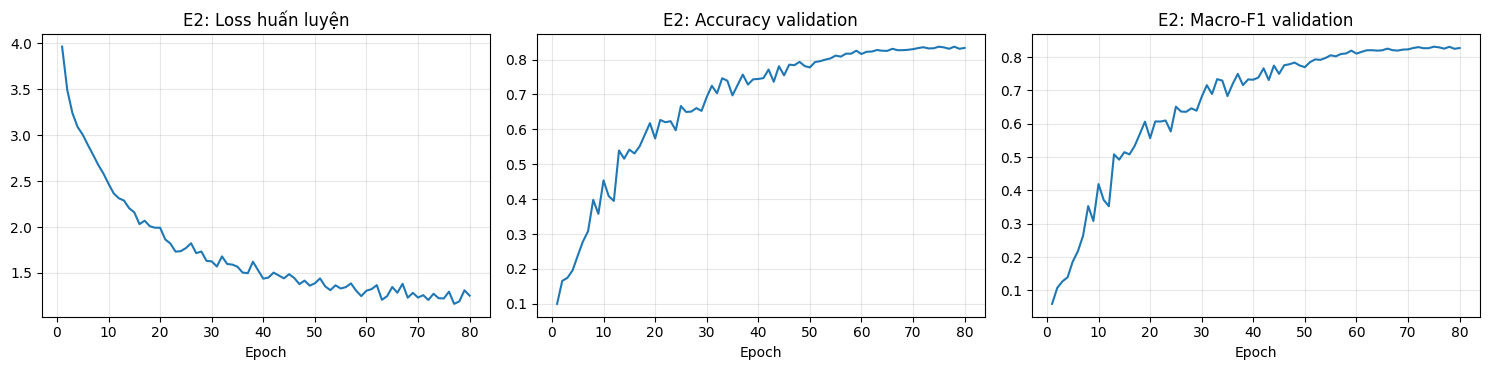

In [5]:
show_exp(EXP_ID)